# Cost of Living Visualiser — Data Exploration

First look at the price dataset: clean it, build one row per country, and compare salaries with an estimated monthly cost of living (rent, bills, transport, groceries and leisure).

run in terminal and restart kernel
```pip install numpy pandas matplotlib plotly nbformat```

In [24]:
# Imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from IPython.display import display

%matplotlib inline
pio.renderers.default = 'iframe_connected'  # show Plotly charts in any Jupyter version

colour_blue = '#0072B2'
colour_green = '#009E73'
colour_orange = '#D55E00'

## Load and inspect the raw CSV

In [25]:
df = pd.read_csv('../data/europe_allyouneed.csv', encoding='utf-8-sig')  # utf-8-sig removes the hidden character before 'item'

print('Shape:', df.shape)
print('Countries:', df['country'].nunique(), '| Items:', df['item'].nunique())
display(df.head())

Shape: (1998, 5)
Countries: 37 | Items: 53


,item,category,price,price_range,country
0,Meal at an Inexpensive Restaurant,eat out,€25.70,€16.15-€44.05,Iceland
1,Meal for Two at a Mid-Range Restaurant (Three ...,eat out,€110.13,€73.42-€220.26,Iceland
2,Combo Meal at McDonald's (or Equivalent Fast-F...,eat out,€21.62,€18.36-€25.70,Iceland
3,Domestic Draft Beer (0.5 Liter),eat out,€11.01,€7.34-€12.85,Iceland
4,Imported Beer (0.33 Liter Bottle),eat out,€11.01,€7.34-€13.22,Iceland


In [26]:
df.info()
display(df.isna().sum().sort_values(ascending=False).to_frame('missing'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1998 entries, 0 to 1997
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   item         1998 non-null   object
 1   category     1998 non-null   object
 2   price        1985 non-null   object
 3   price_range  1924 non-null   object
 4   country      1998 non-null   object
dtypes: object(5)
memory usage: 78.2+ KB


,missing
price_range,74
price,13
item,0
category,0
country,0


**Current Dataset State**

- One row = one item price in one country (long format)
- `price` was read as text because values contain "€" and thousands separators (e.g. `€61,600.59`)
- `price` is missing only for **Minimum Wage** in some countries (countries without a statutory minimum wage)
- `price_range` is missing more often — we only use it as supporting information
- `price_range` contains outliers so the feature itself may not be as useful

## Clean the prices

Remove "€" and `,`, then convert to numbers.

In [27]:
df['price'] = pd.to_numeric(df['price'].str.replace('€', '', regex=False)
                                       .str.replace(',', '', regex=False), errors='coerce')

print('Duplicate rows:', df.duplicated().sum())
display(df.loc[df['price'] == 0, ['item', 'country', 'price']])

Duplicate rows: 0


,item,country,price
664,Monthly Public Transport Pass (Regular Price),Malta,0.0


**Finding:** Malta's monthly public transport pass is €0. This is plausible rather than an error — Malta made public transport free for residents in 2022 — so the value is kept.

## One row per country

Some items are already monthly prices (rent, utilities, internet, mobile, transport pass). Groceries and leisure are **unit prices**, so they are multiplied by an estimated **monthly quantity for one adult** (the baskets below — our estimate, to be agreed by the group).

monthly cost = rent (1-bed) + bills (utilities + internet + mobile) + transport pass + groceries + leisure

money left = net salary − monthly cost

In [28]:
items = {
    'Average Monthly Net Salary (After Tax)': 'net_salary',
    'Minimum Wage': 'minimum_wage',
    '1 Bedroom Apartment Outside of City Centre': 'rent',
    '1 Bedroom Apartment in City Centre': 'rent_centre',
    'Basic Utilities for 85 m2 Apartment (Electricity, Heating, Cooling, Water, Garbage)': 'utilities',
    'Broadband Internet (Unlimited Data, 60 Mbps or Higher)': 'internet',
    'Mobile Phone Plan (Monthly, with Calls and 10GB+ Data)': 'mobile',
    'Monthly Public Transport Pass (Regular Price)': 'transport',
}

countries = (df[df['item'].isin(items)]
             .pivot(index='country', columns='item', values='price')
             .rename(columns=items)
             .rename_axis(columns=None)
             .reset_index())
countries = countries[['country'] + list(items.values())]

# Monthly quantities for one adult: (category, item): quantity
# The category is included because "Imported Beer" appears in both groceries and eat out.
grocery_basket = {
    ('groceries', 'Milk (Regular, 1 Liter)'): 8,
    ('groceries', 'Fresh White Bread (500 g Loaf)'): 6,
    ('groceries', 'White Rice (1 kg)'): 1.5,
    ('groceries', 'Eggs (12, Large Size)'): 3,
    ('groceries', 'Local Cheese (1 kg)'): 0.75,
    ('groceries', 'Chicken Fillets (1 kg)'): 2.5,
    ('groceries', 'Beef Round or Equivalent Back Leg Red Meat (1 kg)'): 1,
    ('groceries', 'Apples (1 kg)'): 2,
    ('groceries', 'Bananas (1 kg)'): 2,
    ('groceries', 'Oranges (1 kg)'): 2,
    ('groceries', 'Tomatoes (1 kg)'): 2,
    ('groceries', 'Potatoes (1 kg)'): 4,
    ('groceries', 'Onions (1 kg)'): 1,
    ('groceries', 'Lettuce (1 Head)'): 4,
    ('groceries', 'Bottled Water (1.5 Liter)'): 10,
}
leisure_basket = {
    ('sport_and_leis', 'Monthly Fitness Club Membership'): 1,
    ('sport_and_leis', 'Cinema Ticket (International Release)'): 2,
    ('eat out', 'Meal at an Inexpensive Restaurant'): 4,
    ('eat out', 'Cappuccino (Regular Size)'): 8,
}

def basket_cost(basket):
    # price of each item x its monthly quantity, added up per country
    parts = [df[(df['category'] == cat) & (df['item'] == item)].set_index('country')['price'] * qty
             for (cat, item), qty in basket.items()]
    return sum(parts)

countries['groceries'] = countries['country'].map(basket_cost(grocery_basket))
countries['leisure'] = countries['country'].map(basket_cost(leisure_basket))
countries['bills'] = countries['utilities'] + countries['internet'] + countries['mobile']

countries['monthly_cost'] = countries[['rent', 'bills', 'transport', 'groceries', 'leisure']].sum(axis=1)
countries['money_left'] = countries['net_salary'] - countries['monthly_cost']
countries['cost_pct_of_salary'] = (countries['monthly_cost'] / countries['net_salary'] * 100).round(1)
countries['rent_pct_of_salary'] = (countries['rent'] / countries['net_salary'] * 100).round(1)
countries['left_on_min_wage'] = countries['minimum_wage'] - countries['monthly_cost']  # missing where there is no minimum wage

display(countries.sort_values('money_left', ascending=False).round(0))

,country,net_salary,minimum_wage,rent,rent_centre,utilities,internet,mobile,transport,groceries,leisure,bills,monthly_cost,money_left,cost_pct_of_salary,rent_pct_of_salary,left_on_min_wage
34,Switzerland,6382.0,NaN,1438.0,1775.0,249.0,51.0,34.0,89.0,234.0,270.0,334.0,2365.0,4017.0,37.0,22.0,NaN
7,Denmark,3678.0,NaN,807.0,1002.0,194.0,36.0,15.0,80.0,162.0,201.0,245.0,1494.0,2183.0,41.0,22.0,NaN
24,Norway,3773.0,NaN,979.0,1252.0,246.0,66.0,35.0,75.0,205.0,201.0,348.0,1808.0,1965.0,48.0,26.0,NaN
14,Iceland,4250.0,NaN,1757.0,2207.0,91.0,80.0,29.0,85.0,239.0,264.0,200.0,2545.0,1705.0,60.0,41.0,NaN
11,Germany,2921.0,2343.0,628.0,810.0,305.0,43.0,22.0,63.0,133.0,150.0,370.0,1344.0,1577.0,46.0,22.0,999.0
33,Sweden,2718.0,NaN,618.0,775.0,118.0,34.0,24.0,74.0,147.0,148.0,176.0,1163.0,1555.0,43.0,23.0,NaN
22,Netherlands,3389.0,2338.0,1162.0,1468.0,231.0,45.0,20.0,90.0,136.0,174.0,296.0,1858.0,1531.0,55.0,34.0,480.0
9,Finland,2669.0,NaN,631.0,774.0,127.0,22.0,25.0,63.0,144.0,165.0,174.0,1177.0,1491.0,44.0,24.0,NaN
2,Belgium,2717.0,2234.0,768.0,882.0,207.0,48.0,20.0,55.0,137.0,168.0,275.0,1404.0,1313.0,52.0,28.0,830.0
36,United Kingdom,2995.0,NaN,977.0,1202.0,289.0,38.0,16.0,96.0,122.0,173.0,343.0,1711.0,1285.0,57.0,33.0,NaN


## Static chart — how much of a salary goes on rent?

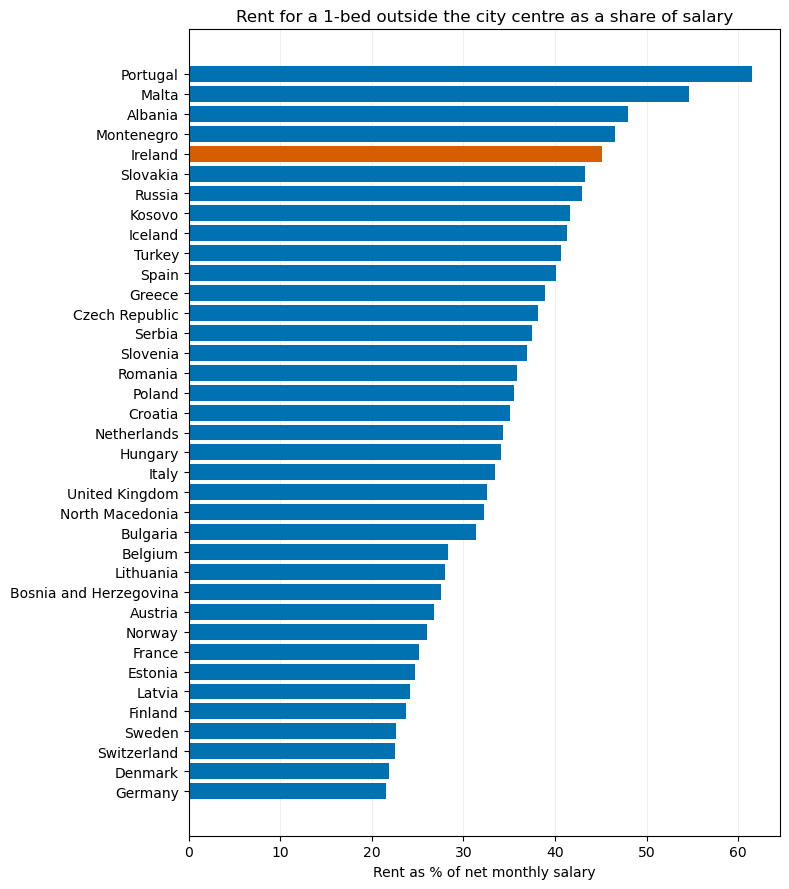

In [29]:
by_rent = countries.sort_values('rent_pct_of_salary')
colours = [colour_orange if c == 'Ireland' else colour_blue for c in by_rent['country']]

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(by_rent['country'], by_rent['rent_pct_of_salary'], color=colours)
ax.set_xlim(left=0)
ax.set_xlabel('Rent as % of net monthly salary')
ax.set_title('Rent for a 1-bed outside the city centre as a share of salary')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Interactive chart 1 — money left after monthly costs

Hover over a bar to see the salary and cost behind it.

In [30]:
countries['status'] = np.where(countries['money_left'] >= 0, 'Money left', 'Short')

fig_left = px.bar(
    countries.sort_values('money_left'), x='money_left', y='country', orientation='h',
    color='status', color_discrete_map={'Money left': colour_green, 'Short': colour_orange},
    hover_data={'net_salary': ':,.0f', 'monthly_cost': ':,.0f', 'money_left': ':,.0f', 'status': False},
    labels={'money_left': 'Money left (€)', 'country': 'Country',
            'net_salary': 'Net salary (€)', 'monthly_cost': 'Monthly cost (€)'},
    title='Net salary minus rent, bills, transport, groceries and leisure', height=850,
)
fig_left.update_layout(template='plotly_white', showlegend=False)
fig_left.show()

## Interactive chart 2 — do higher salaries come with higher rent?

Each point is a country. Hover for details; drag to zoom, double-click to reset.

In [31]:
fig_scatter = px.scatter(
    countries, x='net_salary', y='rent', hover_name='country',
    hover_data={'net_salary': ':,.0f', 'rent': ':,.0f', 'rent_pct_of_salary': ':.1f'},
    labels={'net_salary': 'Net monthly salary (€)', 'rent': 'Rent, 1-bed outside centre (€)',
            'rent_pct_of_salary': 'Rent as % of salary'},
    title='Net salary vs rent by country',
)
fig_scatter.update_traces(marker={'size': 11, 'color': colour_blue})
fig_scatter.update_layout(template='plotly_white')
fig_scatter.show()

print('Correlation:', round(countries['net_salary'].corr(countries['rent']), 2))

Correlation: 0.86


## Static chart — can the average salary cover the cost of living?

Grouped bars: net salary next to the estimated monthly cost for each country, both from a zero baseline.

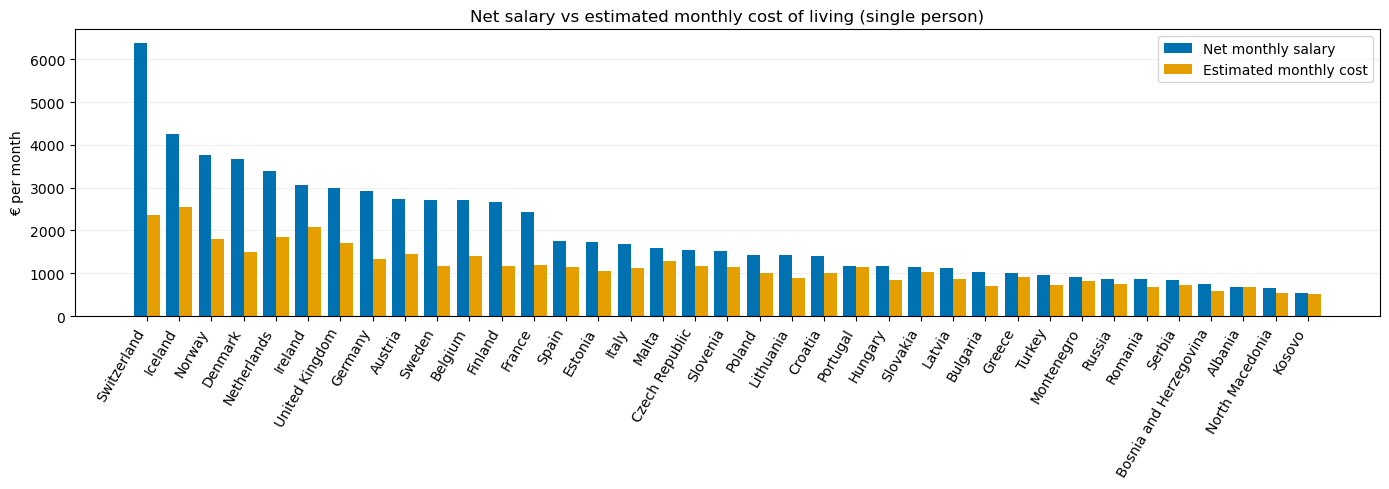

In [32]:
ordered = countries.sort_values('net_salary', ascending=False).reset_index(drop=True)
x = np.arange(len(ordered))
w = 0.4

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - w / 2, ordered['net_salary'], width=w, label='Net monthly salary', color=colour_blue)
ax.bar(x + w / 2, ordered['monthly_cost'], width=w, label='Estimated monthly cost', color='#E69F00')
ax.set_xticks(x)
ax.set_xticklabels(ordered['country'], rotation=60, ha='right')
ax.set_ylabel('€ per month')
ax.set_title('Net salary vs estimated monthly cost of living (single person)')
ax.legend()
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Static chart — what makes up the cost of living?

A stacked bar shows the total and its parts: rent, bills (utilities + internet + mobile), transport pass, groceries and leisure. Sorted by total cost; rent at the bottom so the biggest part shares a common baseline.

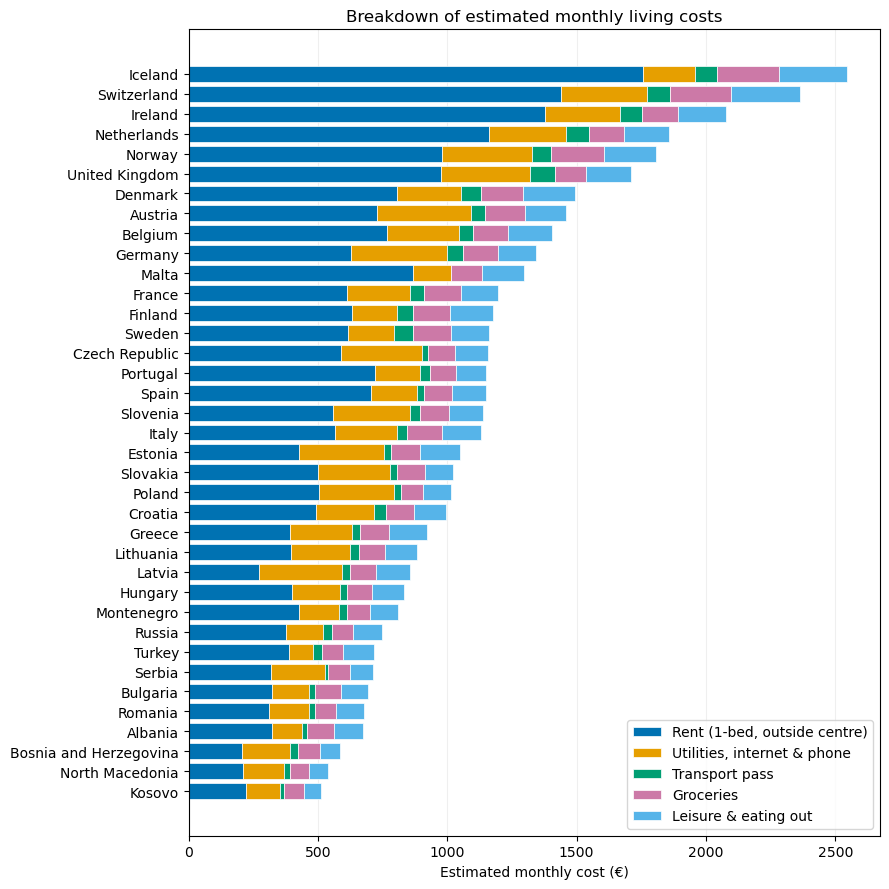

In [33]:
cost_parts = {'rent': 'Rent (1-bed, outside centre)', 'bills': 'Utilities, internet & phone',
              'transport': 'Transport pass', 'groceries': 'Groceries', 'leisure': 'Leisure & eating out'}
part_colours = {'rent': colour_blue, 'bills': '#E69F00', 'transport': colour_green,
                'groceries': '#CC79A7', 'leisure': '#56B4E9'}

by_cost = countries.sort_values('monthly_cost')
fig, ax = plt.subplots(figsize=(9, 9))
left = np.zeros(len(by_cost))
for part, label in cost_parts.items():
    ax.barh(by_cost['country'], by_cost[part], left=left, label=label,
            color=part_colours[part], edgecolor='white', linewidth=0.5)
    left = left + by_cost[part].to_numpy()

ax.set_xlim(left=0)
ax.set_xlabel('Estimated monthly cost (€)')
ax.set_title('Breakdown of estimated monthly living costs')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Static chart — how much of the salary does the cost of living take?

Monthly cost as a percentage of net salary, with Ireland highlighted. Above 100% the average salary would not cover the estimated costs.

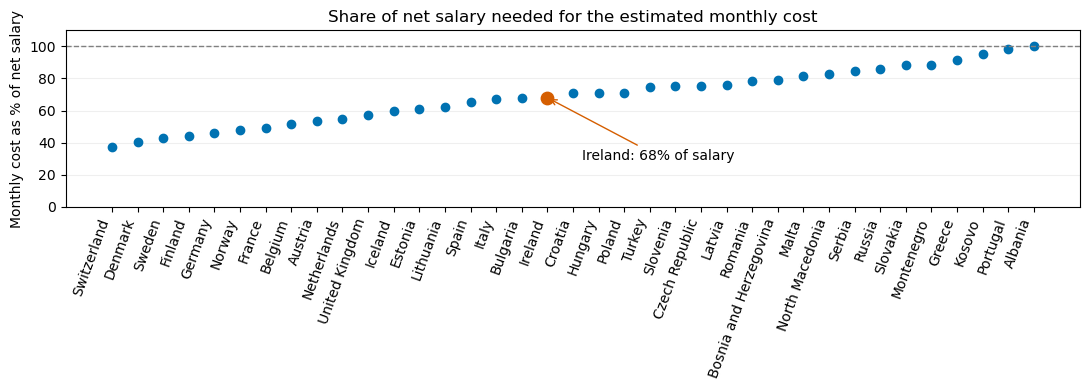

In [34]:
by_share = countries.sort_values('cost_pct_of_salary').reset_index(drop=True)
target = by_share.loc[by_share['country'] == 'Ireland'].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(by_share['country'], by_share['cost_pct_of_salary'], marker='o', linestyle='none', color=colour_blue)
ax.scatter([target['country']], [target['cost_pct_of_salary']], color=colour_orange, s=80, zorder=5)
ax.annotate(f"Ireland: {target['cost_pct_of_salary']:.0f}% of salary",
            xy=(target['country'], target['cost_pct_of_salary']), xytext=(25, -45),
            textcoords='offset points', arrowprops={'arrowstyle': '->', 'color': colour_orange})
ax.axhline(100, linestyle='--', color='grey', linewidth=1)
ax.set_ylim(0, max(110, by_share['cost_pct_of_salary'].max() + 10))
plt.setp(ax.get_xticklabels(), rotation=70, ha='right')
ax.set_ylabel('Monthly cost as % of net salary')
ax.set_title('Share of net salary needed for the estimated monthly cost')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## Static chart — rent in the city centre vs outside

Histograms of the 37 country values for a 1-bed apartment, with the same bins so the two panels can be compared. The dashed line is the median.

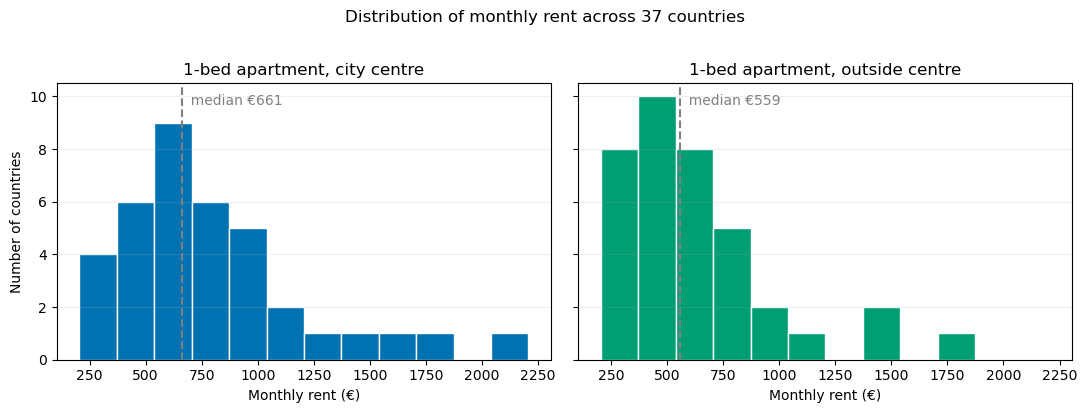

In [35]:
bins = np.histogram_bin_edges(pd.concat([countries['rent_centre'], countries['rent']]), bins=12)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
axes[0].hist(countries['rent_centre'], bins=bins, color=colour_blue, edgecolor='white')
axes[0].set_title('1-bed apartment, city centre')
axes[1].hist(countries['rent'], bins=bins, color=colour_green, edgecolor='white')
axes[1].set_title('1-bed apartment, outside centre')
for ax, column in zip(axes, ['rent_centre', 'rent']):
    median = countries[column].median()
    ax.axvline(median, linestyle='--', color='grey')
    ax.text(median, ax.get_ylim()[1] * 0.92, f'  median €{median:,.0f}', color='grey')
    ax.set_xlabel('Monthly rent (€)')
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Number of countries')
fig.suptitle('Distribution of monthly rent across 37 countries', y=1.02)
fig.tight_layout()
plt.show()

## Static chart — money left on the minimum wage

Minimum wage is missing for 13 countries, so they are **left out rather than set to zero**. The values are most likely gross (before tax) while costs are paid from net income, so this view overstates what a minimum-wage worker has left.

24 of 37 countries have a minimum wage value.


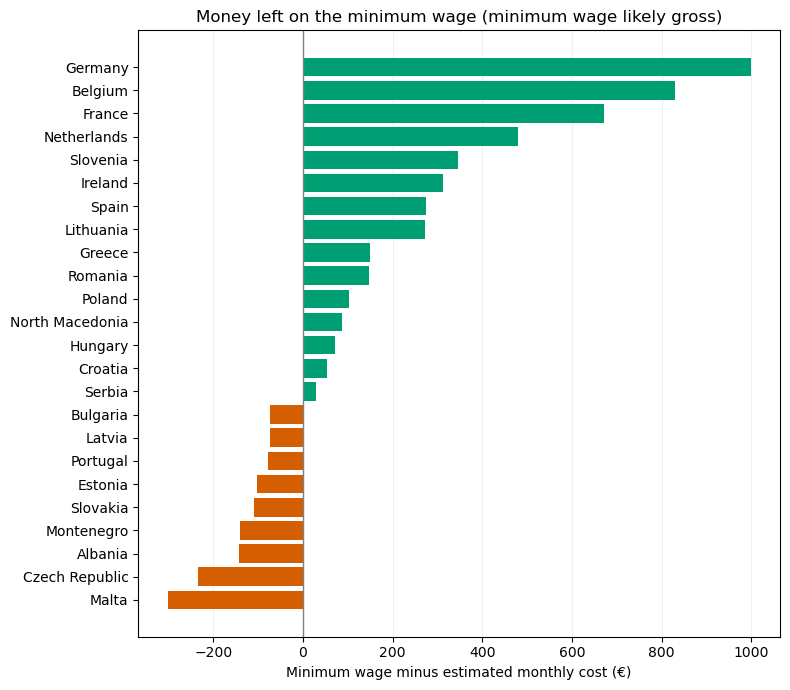

In [36]:
min_wage = countries.dropna(subset=['minimum_wage'])
print(f'{len(min_wage)} of {len(countries)} countries have a minimum wage value.')

by_min = min_wage.sort_values('left_on_min_wage')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_min['country'], by_min['left_on_min_wage'],
        color=np.where(by_min['left_on_min_wage'] >= 0, colour_green, colour_orange))
ax.axvline(0, color='grey', linewidth=1)
ax.set_xlabel('Minimum wage minus estimated monthly cost (€)')
ax.set_title('Money left on the minimum wage (minimum wage likely gross)')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Notes

- Groceries and leisure use **estimated monthly quantities** for one adult (the baskets in the country table); changing them changes the results.
- Minimum wage is missing for 13 countries and is probably gross (before tax), so money left on the minimum wage is overstated.
- Utilities are quoted for an 85 m² apartment, which is larger than a 1-bed.
- Average net salary is not everyone's income, and national averages hide differences between cities.
- A link between salary and rent is not proof that one causes the other.